# Data Mining Project : UJJWAL DAHAL (THA079BEI046)

# A Comparative Study of Machine Learning Algorithms for Heart Disease Prediction



## Original Paper : Performance Evaluation of Machine Learning Techniques (MLT) for Heart Disease Prediction

# 1. Dataset Loading

### Official Link of Cleveland Heart Dataset : [CLICK ME](https://archive.ics.uci.edu/dataset/45/heart+disease)

* Zip file lai Extract garne
* `"processed.cleveland.data"` Hamilai chaine Dataset ho
* यो data Comma-Separated cha and Column Name chaina
* So Hamro First Task:

  * CSV File ma Convert garne
  * Column Name dine


In [1]:
from google.colab import files

uploaded = files.upload()

Saving processed.cleveland.data to processed.cleveland.data



* Zip folder ma `heart-disease.names` File Cha, Tesbata Column Name Haru Dine


In [2]:
import pandas as pd

# Official UCI Cleveland attribute names
columns = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "num"
]

df = pd.read_csv(
    "processed.cleveland.data",
    names=columns,
    na_values="?" #data ma "?" bhaeko Value lai NaN bhanera indicate garna lai
)

df.to_csv("processed.cleveland.csv", index=False)

print("CSV created successfully")
print("Shape:", df.shape)
print(df.head())

CSV created successfully
Shape: (303, 14)
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  num  
0    3.0  0.0   6.0    0  
1    2.0  3.0   3.0    2  
2    2.0  2.0   7.0    1  
3    3.0  0.0   3.0    0  
4    1.0  0.0   3.0    0  


In [3]:
# CSV File banako lai Load garne

df = pd.read_csv("processed.cleveland.csv")

df.head(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
5,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0
6,62.0,0.0,4.0,140.0,268.0,0.0,2.0,160.0,0.0,3.6,3.0,2.0,3.0,3
7,57.0,0.0,4.0,120.0,354.0,0.0,0.0,163.0,1.0,0.6,1.0,0.0,3.0,0
8,63.0,1.0,4.0,130.0,254.0,0.0,2.0,147.0,0.0,1.4,2.0,1.0,7.0,2
9,53.0,1.0,4.0,140.0,203.0,1.0,2.0,155.0,1.0,3.1,3.0,0.0,7.0,1


# Column ko Barema

The original UCI database contains **76 attributes**, but the Cleveland dataset commonly used for Machine Learning contains **14 attributes**.

## 14 Used Attributes

| # | Column | Description |
|---|---|---|
| 1 | `age` | Patient age in years |
| 2 | `sex` | `1 = male`, `0 = female` |
| 3 | `cp` | Chest pain type |
| 4 | `trestbps` | Resting blood pressure (mm Hg) |
| 5 | `chol` | Serum cholesterol (mg/dl) |
| 6 | `fbs` | Fasting blood sugar > 120 mg/dl (`1 = true`, `0 = false`) |
| 7 | `restecg` | Resting ECG results |
| 8 | `thalach` | Maximum heart rate achieved |
| 9 | `exang` | Exercise-induced angina (`1 = yes`, `0 = no`) |
| 10 | `oldpeak` | ST depression induced by exercise |
| 11 | `slope` | Slope of the peak exercise ST segment |
| 12 | `ca` | Number of major vessels colored by fluoroscopy (`0–3`) |
| 13 | `thal` | Thalassemia result |
| 14 | `num` | Heart disease diagnosis / Target |

## Categorical Values

```text
cp (Chest Pain Type):
-> Esma 4 ta Categories chan:
1 = Typical angina
2 = Atypical angina
3 = Non-anginal pain
4 = Asymptomatic

restecg (Resting Electrocardiographic Results):
0 = Normal
1 = ST-T wave abnormality
2 = Left ventricular hypertrophy

slope (Slope of the peak exercise ST segment):
1 = Upsloping
2 = Flat
3 = Downsloping

thal (Thalassemia):
3 = Normal
6 = Fixed defect
7 = Reversible defect


#-> "num" Column : Target Column

0 = No presence of heart disease
1 = Heart disease
2 = Heart disease
3 = Heart disease
4 = Heart disease

-> so Our Problem is Binary Classification

In [4]:
# Since Target Column ma 4 ta Values chan jasma 0 means No Presence of Heart Disease
# and 1,2,3,4 means Heart Disease so 4 tai lai 1 le represent garne

#"target" Column banako

df["target"] = (df["num"] > 0).astype(int)
df.drop(columns=["num"], inplace=True) #num Column lai delete

In [5]:
df.sample(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
86,47.0,1.0,3.0,138.0,257.0,0.0,2.0,156.0,0.0,0.0,1.0,0.0,3.0,0
155,70.0,1.0,4.0,130.0,322.0,0.0,2.0,109.0,0.0,2.4,2.0,3.0,3.0,1
295,41.0,1.0,2.0,120.0,157.0,0.0,0.0,182.0,0.0,0.0,1.0,0.0,3.0,0
94,63.0,0.0,3.0,135.0,252.0,0.0,2.0,172.0,0.0,0.0,1.0,0.0,3.0,0
270,61.0,1.0,4.0,140.0,207.0,0.0,2.0,138.0,1.0,1.9,1.0,1.0,7.0,1
244,60.0,0.0,3.0,120.0,178.0,1.0,0.0,96.0,0.0,0.0,1.0,0.0,3.0,0
19,49.0,1.0,2.0,130.0,266.0,0.0,0.0,171.0,0.0,0.6,1.0,0.0,3.0,0
263,44.0,1.0,3.0,120.0,226.0,0.0,0.0,169.0,0.0,0.0,1.0,0.0,3.0,0
277,39.0,0.0,3.0,138.0,220.0,0.0,0.0,152.0,0.0,0.0,2.0,0.0,3.0,0
140,59.0,1.0,2.0,140.0,221.0,0.0,0.0,164.0,1.0,0.0,1.0,0.0,3.0,0


In [6]:
df.shape

# 303 Rows , 14 Columns

(303, 14)

In [7]:
#Column names hernalai

print("Column Names:")
print(df.columns.tolist())

Column Names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


# 2. Dataset Understanding + Missing Values Check

In [8]:
#data types check garna lai

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [9]:
#processed.cleaveland.data ma Row 88 ma Null Value cha i.e "?" so Checking this Row

df.iloc[87]

,87
age,53.0
sex,0.0
cp,3.0
trestbps,128.0
chol,216.0
fbs,0.0
restecg,2.0
thalach,115.0
exang,0.0
oldpeak,0.0


In [10]:
# missing values kati cha herna lai

df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [11]:
# Duplicate Rows check garnalai

df.duplicated().sum()

np.int64(0)

In [12]:
# Target Class ko distribution hernalai

df["target"].value_counts()

,count
target,
0,164
1,139


In [13]:
print(df["target"].value_counts(normalize=True) * 100)

target
0    54.125413
1    45.874587
Name: proportion, dtype: float64


# 3. Data Preprocessing

## 3.1 Handle Missing Values

-> Hamro dataset ma dherai rows chaina, only 303 cha so Missing values bhaeko row lai remove garnu bhanda impute (new value le fill garnu) better ho.

-> Since `ca` and `thal` column ma missing values chan and they are categorical columns, so `mode` use garnu better ho to fill empty values.

In [14]:
#actual value herna lai

print("ca mode:", df["ca"].mode()[0])
print("thal mode:", df["thal"].mode()[0])

ca mode: 0.0
thal mode: 3.0


In [15]:
df["ca"] = df["ca"].fillna(df["ca"].mode()[0])
df["thal"] = df["thal"].fillna(df["thal"].mode()[0])

In [16]:
# confirm garna lai

df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [17]:
# rechecking dataset again

df.shape

(303, 14)

In [18]:
df.isnull().sum().sum()

np.int64(0)

In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
# numerical summary

df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.663366,4.722772,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.934375,1.938383,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000


## 3.2 Separate Features and Target

-> abo Dataset lai Input Features (X) and Target(y) ma Seperate garincha

In [21]:
X = df.drop(columns=["target"])
y = df["target"]

In [22]:
# Input Features & Target ko Shape

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (303, 13)
Target Shape: (303,)


In [23]:
# features name

print("Features:")
print(X.columns.tolist())

Features:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [24]:
# target values

print("Target Values:")
print(y.unique())

Target Values:
[0 1]


## 3.3 Identify Numerical and Categorical Features

-> Hamro dataset ma Sabai Values "float64" bhaeni All columns actually "continuous numerical variables" hoena

-> "cp" , "sex" , "fbs" , "restecg" , "exang" , "slope" , "thal" haru Categorical Column ho

-> Since KNN ma "scaling" necessary cha so Categorical Variables lai Continuous Varialble jasari treat garnu hudaina

In [25]:
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

print("Numerical Features:")
print(numerical_features)

Numerical Features:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak']


In [26]:
categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

print("Categorical Features:")
print(categorical_features)

Categorical Features:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


In [27]:
# count checking

print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))
print("Total features:", len(numerical_features) + len(categorical_features))

Number of numerical features: 5
Number of categorical features: 8
Total features: 13


# 4. Exploratory Data Analysis (EDA)

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

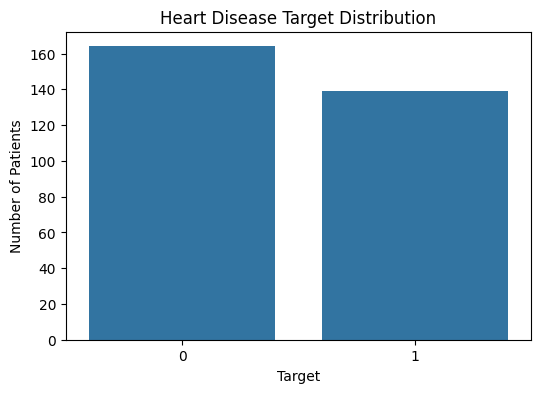

In [29]:
# Target Distribution

plt.figure(figsize=(6, 4))

sns.countplot(x="target", data=df)

plt.title("Heart Disease Target Distribution")
plt.xlabel("Target")
plt.ylabel("Number of Patients")
plt.savefig("heart_disease_target_distribution.png",dpi=300, bbox_inches="tight")
plt.show()

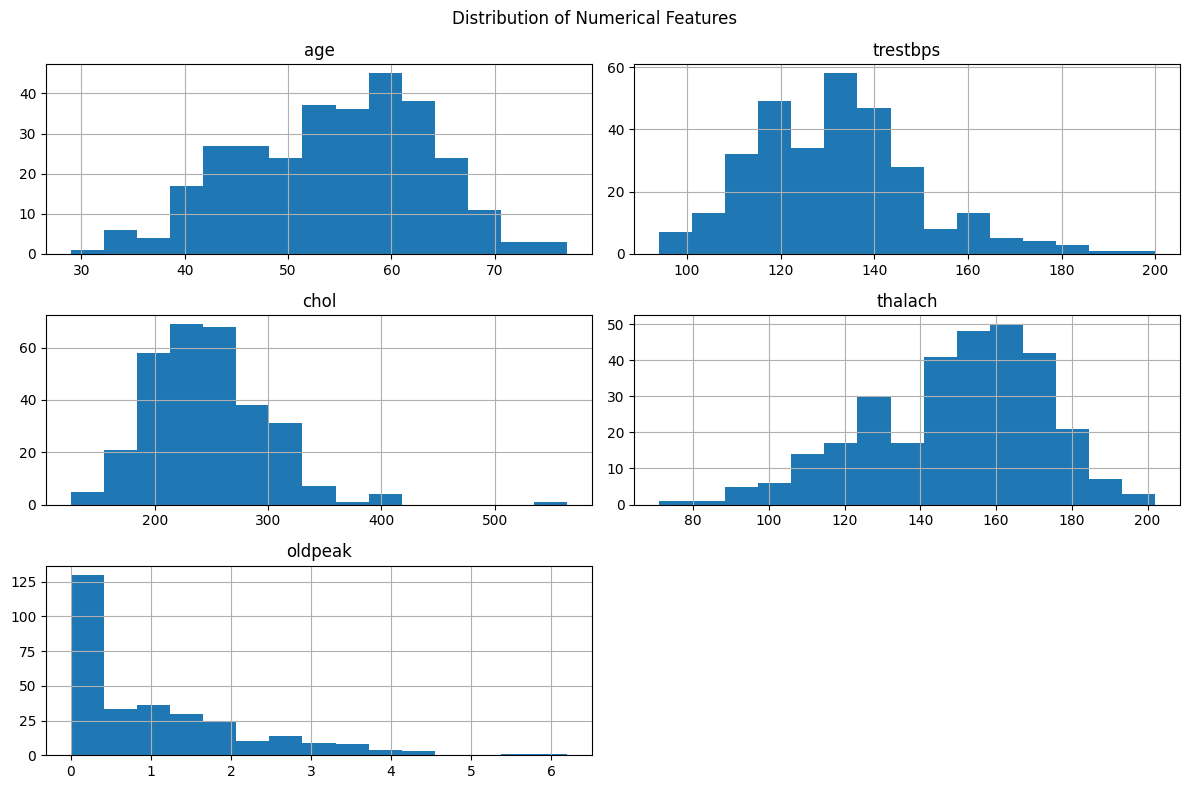

In [30]:
# Numerical Features distribution
#-> 5 ota Numerical Features chan

df[numerical_features].hist(
    figsize=(12, 8),
    bins=15
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.savefig("numerical_features_distribution.png",dpi=300, bbox_inches="tight")
plt.show()

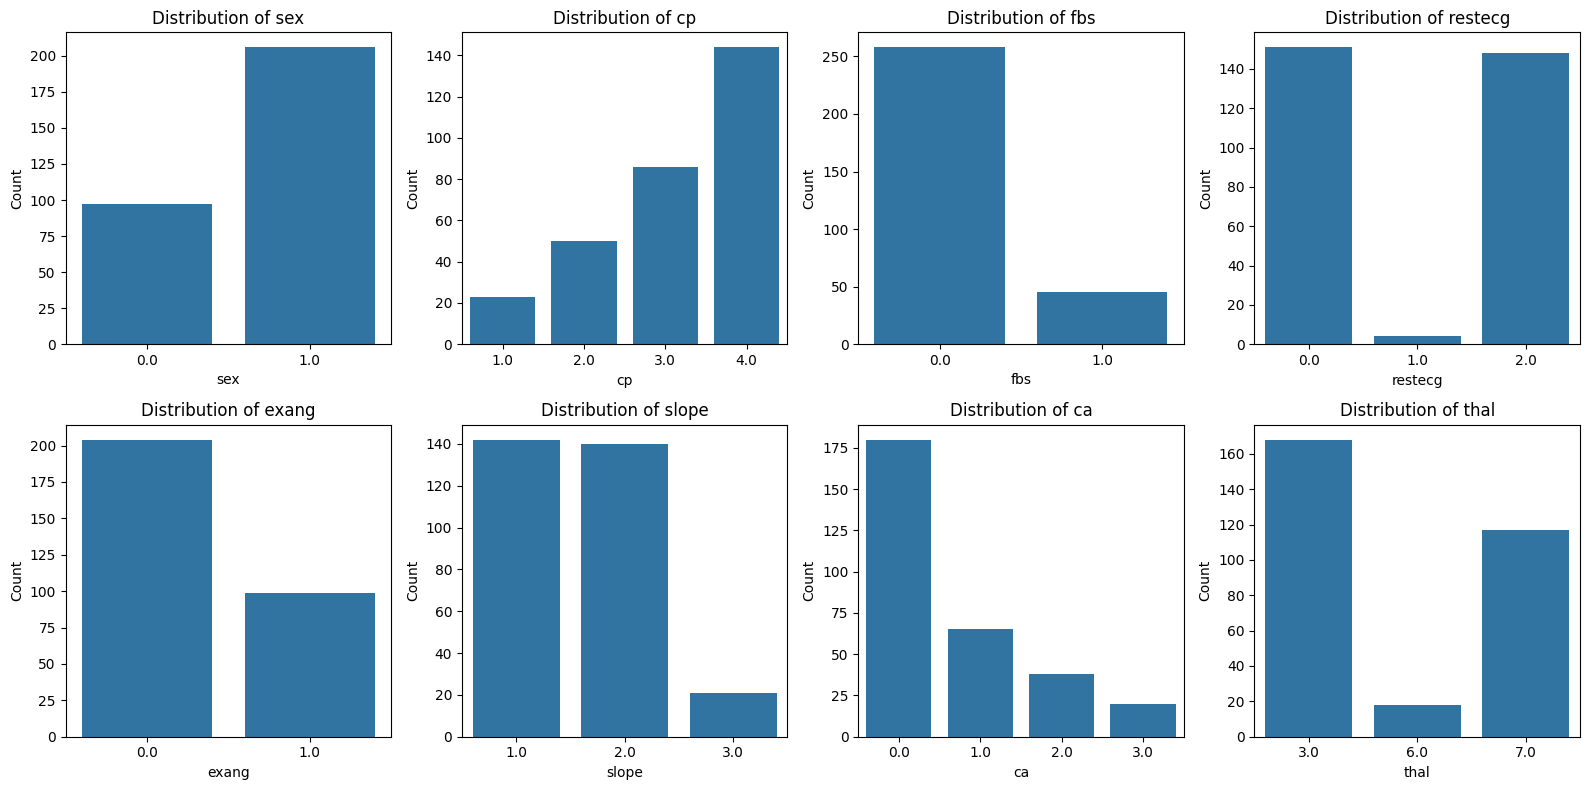

In [31]:
fig, axes = plt.subplots(
    2,
    4,
    figsize=(16, 8)
)

axes = axes.flatten()

for i, feature in enumerate(categorical_features):

    sns.countplot(
        x=feature,
        data=df,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Count")

plt.tight_layout()

plt.savefig(
    "categorical_features_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4.1 Correlation analysis

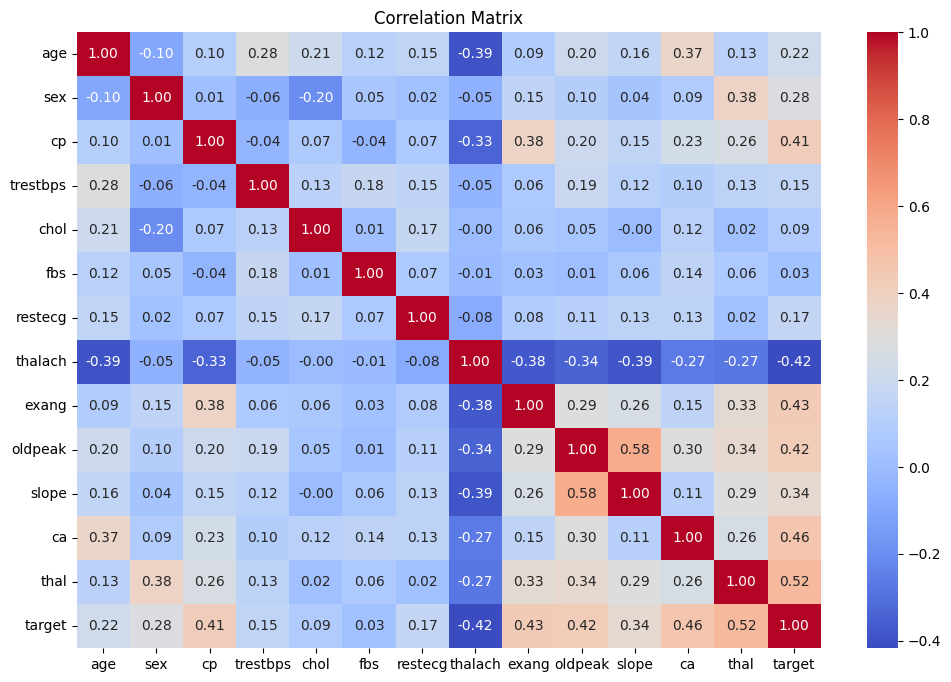

In [32]:
# Correlation Matrix

# -> Features bich Relationship ko lagi
# -> Correlation le Two Variables bichko Linear Relationship dekhaucha
# -> +1 == Strong positive relationship
# -> 0 == Small or No Linear Relationship
# -> -1 == Strong negative Relationship

plt.figure(figsize=(12, 8))

correlation_matrix = df.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.savefig(f"correlation_matrix.png",dpi=300, bbox_inches="tight")
plt.show()

## 4.2 Prepare the Data for Machine Learning

-> Hamro Dataset ma Categorical/Discrete Features haru chan BUT tiniharu ko Numerical Values cha

EXAMPLE :

cp: 1, 2, 3, 4

-> Since hamile KNN , Naive Bayes , Decision Tree use garne bhaekole Model Specific Preprocessing garcham

### -> One Hot Encoding use gardinam Because
### Original Paper le pani categorical variables lai original encoded form maa use gareko cha

In [33]:
#confirming X and y

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (303, 13)
y shape: (303,)


In [34]:
# categorical featurs value check

#-> Categorical Column ma kun kun values haru cha Check gareko

for feature in categorical_features:
    print(feature, ":", sorted(X[feature].unique()))

sex : [np.float64(0.0), np.float64(1.0)]
cp : [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
fbs : [np.float64(0.0), np.float64(1.0)]
restecg : [np.float64(0.0), np.float64(1.0), np.float64(2.0)]
exang : [np.float64(0.0), np.float64(1.0)]
slope : [np.float64(1.0), np.float64(2.0), np.float64(3.0)]
ca : [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]
thal : [np.float64(3.0), np.float64(6.0), np.float64(7.0)]


In [35]:
# Numerical Features ko Range check

for feature in numerical_features:
    print(
        feature,
        "Min:", X[feature].min(),
        "Max:", X[feature].max()
    )

# From Output K thaa bhayo bhane Each Features ko "Scales" farak cha
#-> so We need "Feature Scaling" for Model like KNN

age Min: 29.0 Max: 77.0
trestbps Min: 94.0 Max: 200.0
chol Min: 126.0 Max: 564.0
thalach Min: 71.0 Max: 202.0
oldpeak Min: 0.0 Max: 6.2


# 5. Feature Analysis and Selection Consideration

-> Original Paper ma Feature Selection ko barema Kura gareko cha

-> But Exact Feature Selection Algorithm ko barema Kura gareko chaina

--> so Maile Correlation-based Feature Selection use gardai chu

-> Esma "Target" sanga Feature haruko Correlation herera Relevant Feature select garchau

-> The correlation analysis was used to identify features strongly related to the target. However, no features were removed from the final dataset. All 13 features were retained for model training.

In [36]:
feature_target_corr = (
    df.drop(columns=["target"])
      .corrwith(df["target"])
      .sort_values(key=abs, ascending=False)
)

print(feature_target_corr)

thal        0.522057
ca          0.460033
exang       0.431894
oldpeak     0.424510
thalach    -0.417167
cp          0.414446
slope       0.339213
sex         0.276816
age         0.223120
restecg     0.169202
trestbps    0.150825
chol        0.085164
fbs         0.025264
dtype: float64


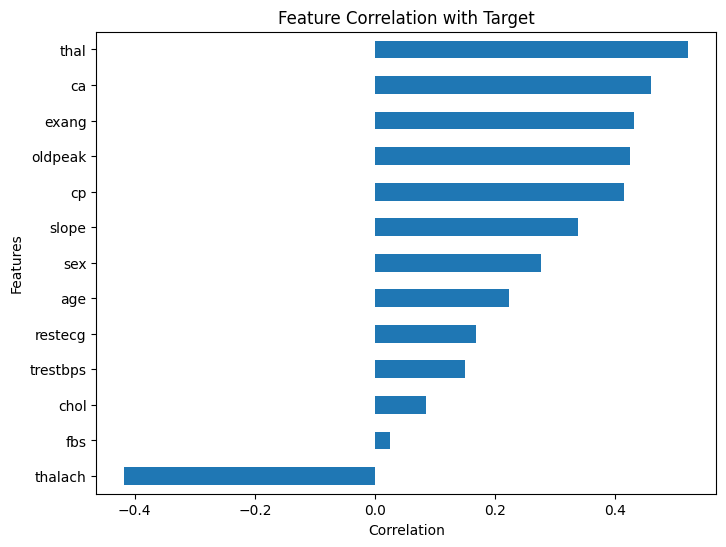

In [37]:
# visualization

plt.figure(figsize=(8, 6))

feature_target_corr.sort_values().plot(kind="barh")

plt.title("Feature Correlation with Target")
plt.xlabel("Correlation")
plt.ylabel("Features")
plt.savefig("feature_correlation_with_target.png",dpi=300, bbox_inches="tight")
plt.show()

-> thal, ca, exang, oldpeak, thalach, and cp show the strongest relationship with the target in our dataset.

-> However, we will not remove fbs, chol, or other low-correlation features yet. A low individual correlation does not automatically mean a feature is useless for a ML model.

# 6. 10-Fold Cross-Validation Setup

-> Original Paper ma : 10-fold corss-validation use gariyeko cha

-> so Dataset lai 10 parts ma Divide garera Each time 9 parts Training & 1 part Validation ko lagi use huncha

In [38]:
from sklearn.model_selection import StratifiedKFold

In [39]:
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

In [40]:
#checking number of folds

print("Number of folds:", cv.get_n_splits())

Number of folds: 10


In [41]:
# checking how folds are created

for fold, (train_index, validation_index) in enumerate(cv.split(X, y), start=1):
    print(
        f"Fold {fold}: "
        f"Training = {len(train_index)}, "
        f"Validation = {len(validation_index)}"
    )

Fold 1: Training = 272, Validation = 31
Fold 2: Training = 272, Validation = 31
Fold 3: Training = 272, Validation = 31
Fold 4: Training = 273, Validation = 30
Fold 5: Training = 273, Validation = 30
Fold 6: Training = 273, Validation = 30
Fold 7: Training = 273, Validation = 30
Fold 8: Training = 273, Validation = 30
Fold 9: Training = 273, Validation = 30
Fold 10: Training = 273, Validation = 30


# 7. KNN Preprocessing: Feature Scaling

-> Since KNN ma distance calculate huncha so Scaling is necessary

-> Paper ma StandardScaler & MinMaxScaler both ko Mention cha so Both garchau

-> Both StandardScaler and MinMaxScaler were examined during preprocessing. StandardScaler was selected for the final KNN implementation.

In [42]:
from sklearn.preprocessing import StandardScaler

In [43]:
train_index, validation_index = next(cv.split(X, y))

X_train_fold = X.iloc[train_index]
X_validation_fold = X.iloc[validation_index]

In [44]:
# Standard Scaler

standard_scaler = StandardScaler()

X_train_standard = standard_scaler.fit_transform(X_train_fold)
X_validation_standard = standard_scaler.transform(X_validation_fold)

In [45]:
# shapes verify

print("StandardScaler:")
print("Training:", X_train_standard.shape)
print("Validation:", X_validation_standard.shape)

StandardScaler:
Training: (272, 13)
Validation: (31, 13)


## 7.1 KNN Model Training + 10-Fold Evaluation

In [46]:
from sklearn.neighbors import KNeighborsClassifier

# KNN ko lagi Hyperparameter Tuning gareko
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

param_grid = {
    "knn__n_neighbors": [3,5,7,9,11,13,15,17,19],
    "knn__weights": ["uniform","distance"],
    "knn__metric": ["euclidean","manhattan"]
}

grid_search_knn = GridSearchCV(pipe, param_grid, cv=10, scoring="accuracy", n_jobs=-1)
grid_search_knn.fit(X, y)

print("Best Parameters:", grid_search_knn.best_params_)
print("Best CV Accuracy:", grid_search_knn.best_score_)

Best Parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 13, 'knn__weights': 'distance'}
Best CV Accuracy: 0.8447311827956989


In [47]:
# at first Accuracy hereko

from sklearn.metrics import accuracy_score

In [48]:
knn_scores = []  # Each fold ko validation accuracy store garne

for fold, (train_index, validation_index) in enumerate(cv.split(X, y), start=1):

    X_train_fold = X.iloc[train_index]
    X_validation_fold = X.iloc[validation_index]

    y_train_fold = y.iloc[train_index]
    y_validation_fold = y.iloc[validation_index]

    # Feature Scaling
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train_fold)
    X_validation_scaled = scaler.transform(X_validation_fold)

    # Tuned KNN model using best parameters
    knn = KNeighborsClassifier(
        n_neighbors=13,
        weights="distance",
        metric="euclidean"
    )

    knn.fit(X_train_scaled, y_train_fold)

    y_pred = knn.predict(X_validation_scaled)

    accuracy = accuracy_score(y_validation_fold, y_pred)

    knn_scores.append(accuracy)

    print(f"Fold {fold}: Accuracy = {accuracy:.4f}")

Fold 1: Accuracy = 0.9032
Fold 2: Accuracy = 0.9032
Fold 3: Accuracy = 0.8065
Fold 4: Accuracy = 0.8000
Fold 5: Accuracy = 0.8333
Fold 6: Accuracy = 0.8000
Fold 7: Accuracy = 0.8667
Fold 8: Accuracy = 0.7333
Fold 9: Accuracy = 0.9000
Fold 10: Accuracy = 0.7333


In [49]:
# average KNN accuracy

import numpy as np

print("KNN Fold Accuracies:", knn_scores)
print("Mean KNN Accuracy:", np.mean(knn_scores))
print("Standard Deviation:", np.std(knn_scores))

KNN Fold Accuracies: [0.9032258064516129, 0.9032258064516129, 0.8064516129032258, 0.8, 0.8333333333333334, 0.8, 0.8666666666666667, 0.7333333333333333, 0.9, 0.7333333333333333]
Mean KNN Accuracy: 0.8279569892473118
Standard Deviation: 0.06162894572433163


## 7.2 KNN Performance Evaluation

In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [51]:
knn_true = []
knn_pred = []

for fold, (train_index, validation_index) in enumerate(cv.split(X, y), start=1):

    X_train_fold = X.iloc[train_index]
    X_validation_fold = X.iloc[validation_index]

    y_train_fold = y.iloc[train_index]
    y_validation_fold = y.iloc[validation_index]

    # Feature Scaling
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train_fold)
    X_validation_scaled = scaler.transform(X_validation_fold)

    # Tuned KNN using GridSearchCV best parameters
    knn = KNeighborsClassifier(
        n_neighbors=13,
        weights="distance",
        metric="euclidean"
    )

    knn.fit(X_train_scaled, y_train_fold)

    y_pred = knn.predict(X_validation_scaled)

    knn_true.extend(y_validation_fold)
    knn_pred.extend(y_pred)

In [52]:
knn_accuracy = accuracy_score(knn_true, knn_pred)

knn_precision = precision_score(knn_true, knn_pred)

knn_recall = recall_score(knn_true, knn_pred)

knn_f1 = f1_score(knn_true, knn_pred)

print("KNN Performance")
print("----------------")
print(f"Accuracy : {knn_accuracy:.4f}")
print(f"Precision: {knn_precision:.4f}")
print(f"Recall   : {knn_recall:.4f}")
print(f"F1-Score : {knn_f1:.4f}")

KNN Performance
----------------
Accuracy : 0.8284
Precision: 0.8425
Recall   : 0.7698
F1-Score : 0.8045


In [53]:
# Confusion Matrix

cm = confusion_matrix(knn_true, knn_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[144  20]
 [ 32 107]]


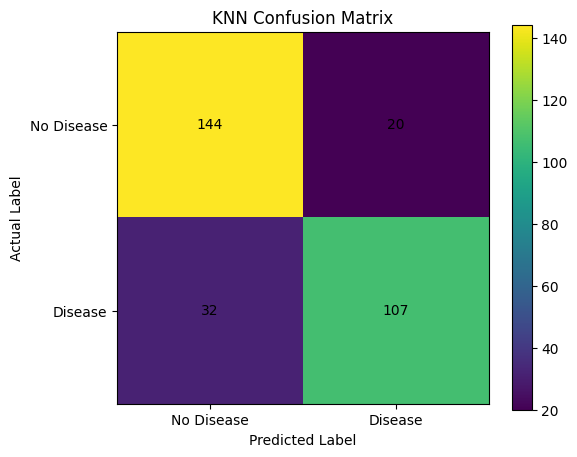

In [54]:
# visually

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.imshow(cm)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["No Disease", "Disease"])
plt.yticks([0, 1], ["No Disease", "Disease"])

plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.savefig("knn_confusion_matrix.png",dpi=300, bbox_inches="tight")
plt.show()

In [55]:
#classification report

print(classification_report(
    knn_true,
    knn_pred,
    target_names=["No Disease", "Disease"]
))

              precision    recall  f1-score   support

  No Disease       0.82      0.88      0.85       164
     Disease       0.84      0.77      0.80       139

    accuracy                           0.83       303
   macro avg       0.83      0.82      0.83       303
weighted avg       0.83      0.83      0.83       303



# 8. Naive Bayes Model

-> Hamro Features Numerical Values haru ma chan so

--> GaussianNB use gareko

In [56]:
from sklearn.naive_bayes import GaussianNB

# Hyperparameter Tunning gareko
from sklearn.model_selection import GridSearchCV

param_grid = {
    "var_smoothing": [
        1e-11,
        1e-10,
        1e-9,
        1e-8,
        1e-7,
        1e-6,
        1e-5
    ]
}

nb = GaussianNB()

grid_search_nb = GridSearchCV(
    estimator=nb,
    param_grid=param_grid,
    cv=10,
    scoring="accuracy",
    n_jobs=-1
)

grid_search_nb.fit(X, y)

print("Best Parameters:", grid_search_nb.best_params_)
print("Best CV Accuracy:", grid_search_nb.best_score_)

Best Parameters: {'var_smoothing': 1e-11}
Best CV Accuracy: 0.8479569892473118


In [57]:
nb_scores = []

for fold, (train_index, validation_index) in enumerate(cv.split(X, y), start=1):

    X_train_fold = X.iloc[train_index]
    X_validation_fold = X.iloc[validation_index]

    y_train_fold = y.iloc[train_index]
    y_validation_fold = y.iloc[validation_index]

    # Tuned Naive Bayes model
    nb = GaussianNB(
        var_smoothing=1e-11
    )

    nb.fit(X_train_fold, y_train_fold)

    y_pred = nb.predict(X_validation_fold)

    accuracy = accuracy_score(y_validation_fold, y_pred)

    nb_scores.append(accuracy)

    print(f"Fold {fold}: Accuracy = {accuracy:.4f}")

Fold 1: Accuracy = 0.8387
Fold 2: Accuracy = 0.9355
Fold 3: Accuracy = 0.8710
Fold 4: Accuracy = 0.8000
Fold 5: Accuracy = 0.8667
Fold 6: Accuracy = 0.8333
Fold 7: Accuracy = 0.8333
Fold 8: Accuracy = 0.7000
Fold 9: Accuracy = 0.9000
Fold 10: Accuracy = 0.8000


In [58]:
print("Naive Bayes Fold Accuracies:", nb_scores)
print("Mean Naive Bayes Accuracy:", np.mean(nb_scores))
print("Standard Deviation:", np.std(nb_scores))

Naive Bayes Fold Accuracies: [0.8387096774193549, 0.9354838709677419, 0.8709677419354839, 0.8, 0.8666666666666667, 0.8333333333333334, 0.8333333333333334, 0.7, 0.9, 0.8]
Mean Naive Bayes Accuracy: 0.8378494623655914
Standard Deviation: 0.06101769207923155


## 8.1 Naive Bayes Performance Evaluation

In [59]:
nb_true = []
nb_pred = []

for fold, (train_index, validation_index) in enumerate(cv.split(X, y), start=1):

    X_train_fold = X.iloc[train_index]
    X_validation_fold = X.iloc[validation_index]

    y_train_fold = y.iloc[train_index]
    y_validation_fold = y.iloc[validation_index]

    # Tuned Naive Bayes
    nb = GaussianNB(
        var_smoothing=1e-11
    )

    nb.fit(X_train_fold, y_train_fold)

    y_pred = nb.predict(X_validation_fold)

    nb_true.extend(y_validation_fold)
    nb_pred.extend(y_pred)

In [60]:
# performance metrics

nb_accuracy = accuracy_score(nb_true, nb_pred)

nb_precision = precision_score(nb_true, nb_pred)

nb_recall = recall_score(nb_true, nb_pred)

nb_f1 = f1_score(nb_true, nb_pred)

print("Naive Bayes Performance")
print("-----------------------")
print(f"Accuracy : {nb_accuracy:.4f}")
print(f"Precision: {nb_precision:.4f}")
print(f"Recall   : {nb_recall:.4f}")
print(f"F1-Score : {nb_f1:.4f}")

Naive Bayes Performance
-----------------------
Accuracy : 0.8383
Precision: 0.8462
Recall   : 0.7914
F1-Score : 0.8178


In [61]:
# confusion matrix

nb_cm = confusion_matrix(nb_true, nb_pred)

print("Confusion Matrix:")
print(nb_cm)

Confusion Matrix:
[[144  20]
 [ 29 110]]


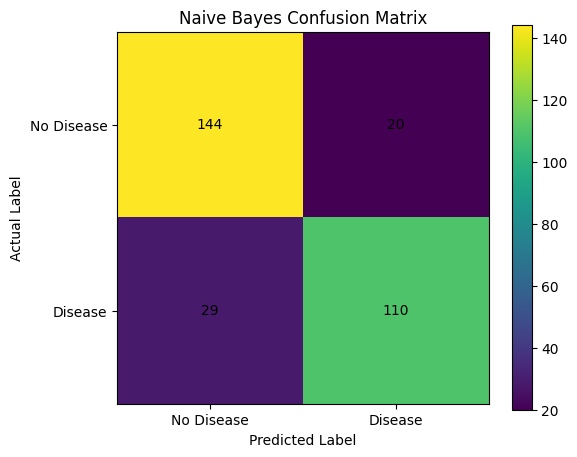

In [62]:
# visualize

plt.figure(figsize=(6, 5))

plt.imshow(nb_cm)

plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["No Disease", "Disease"])
plt.yticks([0, 1], ["No Disease", "Disease"])

plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j, i, nb_cm[i, j], ha="center", va="center")

plt.savefig("naive_byes_confusion_matrix.png",dpi=300, bbox_inches="tight")
plt.show()

In [63]:
print(classification_report(
    nb_true,
    nb_pred,
    target_names=["No Disease", "Disease"]
))

              precision    recall  f1-score   support

  No Disease       0.83      0.88      0.85       164
     Disease       0.85      0.79      0.82       139

    accuracy                           0.84       303
   macro avg       0.84      0.83      0.84       303
weighted avg       0.84      0.84      0.84       303



# 9. Decision Tree Model Training

In [64]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 4, 5, 6],
    "min_samples_split": [5, 10, 15],
    "min_samples_leaf": [2, 5, 10]
}

dt = DecisionTreeClassifier(random_state=42)

grid_search = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=10,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X, y)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 10, 'min_samples_split': 5}
Best CV Accuracy: 0.811505376344086


In [65]:
dt_scores = []

for fold, (train_index, validation_index) in enumerate(cv.split(X, y), start=1):

    X_train_fold = X.iloc[train_index]
    X_validation_fold = X.iloc[validation_index]

    y_train_fold = y.iloc[train_index]
    y_validation_fold = y.iloc[validation_index]

    dt = DecisionTreeClassifier(
        criterion="gini",
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=10,
        random_state=42
    )

    dt.fit(X_train_fold, y_train_fold)

    y_pred = dt.predict(X_validation_fold)

    accuracy = accuracy_score(y_validation_fold, y_pred)

    dt_scores.append(accuracy)

    print(f"Fold {fold}: Accuracy = {accuracy:.4f}")

Fold 1: Accuracy = 0.9032
Fold 2: Accuracy = 0.8710
Fold 3: Accuracy = 0.8387
Fold 4: Accuracy = 0.8333
Fold 5: Accuracy = 0.7667
Fold 6: Accuracy = 0.7000
Fold 7: Accuracy = 0.8333
Fold 8: Accuracy = 0.6667
Fold 9: Accuracy = 0.8667
Fold 10: Accuracy = 0.7000


In [66]:
print("Decision Tree Fold Accuracies:", dt_scores)
print("Mean Decision Tree Accuracy:", np.mean(dt_scores))
print("Standard Deviation:", np.std(dt_scores))

Decision Tree Fold Accuracies: [0.9032258064516129, 0.8709677419354839, 0.8387096774193549, 0.8333333333333334, 0.7666666666666667, 0.7, 0.8333333333333334, 0.6666666666666666, 0.8666666666666667, 0.7]
Mean Decision Tree Accuracy: 0.7979569892473118
Standard Deviation: 0.07918601092687862


## 9.1 Decision Tree Performance Evaluation

In [67]:
dt_true = []
dt_pred = []

for fold, (train_index, validation_index) in enumerate(cv.split(X, y), start=1):

    X_train_fold = X.iloc[train_index]
    X_validation_fold = X.iloc[validation_index]

    y_train_fold = y.iloc[train_index]
    y_validation_fold = y.iloc[validation_index]

    # Tuned Decision Tree
    dt = DecisionTreeClassifier(
        criterion="gini",
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=10,
        random_state=42
    )

    dt.fit(X_train_fold, y_train_fold)

    y_pred = dt.predict(X_validation_fold)

    dt_true.extend(y_validation_fold)
    dt_pred.extend(y_pred)

In [68]:
dt_accuracy = accuracy_score(dt_true, dt_pred)

dt_precision = precision_score(dt_true, dt_pred)

dt_recall = recall_score(dt_true, dt_pred)

dt_f1 = f1_score(dt_true, dt_pred)

print("Decision Tree Performance")
print("------------------------")
print(f"Accuracy : {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall   : {dt_recall:.4f}")
print(f"F1-Score : {dt_f1:.4f}")

Decision Tree Performance
------------------------
Accuracy : 0.7987
Precision: 0.8305
Recall   : 0.7050
F1-Score : 0.7626


In [69]:
dt_cm = confusion_matrix(dt_true, dt_pred)

print("Confusion Matrix:")
print(dt_cm)

Confusion Matrix:
[[144  20]
 [ 41  98]]


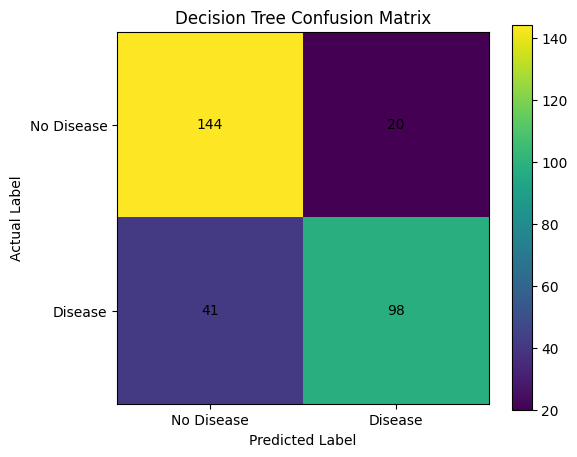

In [70]:
plt.figure(figsize=(6, 5))

plt.imshow(dt_cm)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["No Disease", "Disease"])
plt.yticks([0, 1], ["No Disease", "Disease"])

plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j, i, dt_cm[i, j], ha="center", va="center")

plt.savefig("decision_tree_confusion_matrix.png",dpi=300, bbox_inches="tight")
plt.show()

In [71]:
print(classification_report(
    dt_true,
    dt_pred,
    target_names=["No Disease", "Disease"]
))

              precision    recall  f1-score   support

  No Disease       0.78      0.88      0.83       164
     Disease       0.83      0.71      0.76       139

    accuracy                           0.80       303
   macro avg       0.80      0.79      0.79       303
weighted avg       0.80      0.80      0.80       303



# 10. Final Model Comparison

In [72]:
comparison = pd.DataFrame({
    "Model": ["KNN", "Naive Bayes", "Decision Tree"],
    "Accuracy": [knn_accuracy, nb_accuracy, dt_accuracy],
    "Precision": [knn_precision, nb_precision, dt_precision],
    "Recall": [knn_recall, nb_recall, dt_recall],
    "F1-Score": [knn_f1, nb_f1, dt_f1]
})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,KNN,0.828383,0.842520,0.769784,0.804511
1,Naive Bayes,0.838284,0.846154,0.791367,0.817844
2,Decision Tree,0.798680,0.830508,0.705036,0.762646


In [73]:
comparison_display = comparison.copy()

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

for metric in metrics:
    comparison_display[metric] = (
        comparison_display[metric] * 100
    ).round(2)

comparison_display

,Model,Accuracy,Precision,Recall,F1-Score
0,KNN,82.84,84.25,76.98,80.45
1,Naive Bayes,83.83,84.62,79.14,81.78
2,Decision Tree,79.87,83.05,70.50,76.26


In [74]:
# Best Model

best_accuracy_model = comparison.loc[
    comparison["Accuracy"].idxmax(),
    "Model"
]

best_f1_model = comparison.loc[
    comparison["F1-Score"].idxmax(),
    "Model"
]

print("Best Model based on Accuracy:", best_accuracy_model)
print("Best Model based on F1-Score:", best_f1_model)

Best Model based on Accuracy: Naive Bayes
Best Model based on F1-Score: Naive Bayes


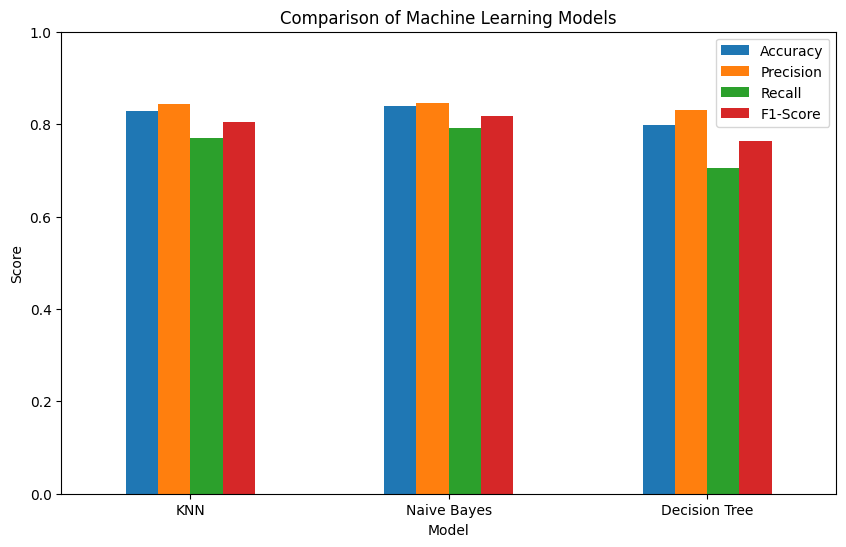

In [75]:
# Comparision Plot

comparison_plot = comparison.copy()

comparison_plot.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend()
plt.savefig("comparision_of_machine_learning_models.png",dpi=300, bbox_inches="tight")
plt.show()

# Final Results Comparison and Paper Reimplementation Analysis

Our machine learning implementation is now complete. In this section, we compare the results of the three tuned models and explain how our implementation follows the methodology of the selected research paper.

## Final Results

The three machine learning models were tuned using **GridSearchCV** and evaluated using **10-Fold Cross-Validation**. The final performance was evaluated using Accuracy, Precision, Recall, and F1-Score.

### 10-Fold Cross-Validation Results

| Model | Accuracy | Precision | Recall | F1-Score |
|---|---:|---:|---:|---:|
| KNN | 82.84% | **84.25%** | 76.98% | 80.45% |
| Naive Bayes | **83.83%** | 84.62% | **79.14%** | **81.78%** |
| Decision Tree | 79.87% | 83.05% | 70.50% | 76.26% |

### Best Hyperparameters

| Model | Best Hyperparameters |
|---|---|
| KNN | `metric=euclidean`, `n_neighbors=13`, `weights=distance` |
| Naive Bayes | `var_smoothing=1e-11` |
| Decision Tree | `criterion=gini`, `max_depth=3`, `min_samples_leaf=10`, `min_samples_split=5` |

## Main Observation

Naive Bayes achieved the **best overall performance** among the three evaluated models.

Its main results were:

- **Accuracy:** 83.83%
- **Precision:** 84.62%
- **Recall:** 79.14%
- **F1-Score:** 81.78%

Naive Bayes also achieved the highest mean accuracy during the 10-Fold Cross-Validation:

- **Naive Bayes:** 83.78% ± 6.10%
- **KNN:** 82.80% ± 6.16%
- **Decision Tree:** 79.80% ± 7.92%

KNN was the second-best performing model, achieving **82.84% Accuracy** and **80.45% F1-Score**. It achieved a Precision of **84.25%** and a Recall of **76.98%**.

Decision Tree achieved the lowest overall performance, with **79.87% Accuracy**, **70.50% Recall**, and **76.26% F1-Score**.

Therefore, based on the overall **10-Fold Cross-Validation results**, **Naive Bayes was selected as the best-performing model** for heart disease prediction.

## Model Stability

The standard deviation of the fold accuracies was also considered to understand the consistency of each model across the 10 folds.

| Model | Mean CV Accuracy | Standard Deviation |
|---|---:|---:|
| KNN | 82.80% | 6.16% |
| Naive Bayes | **83.78%** | **6.10%** |
| Decision Tree | 79.80% | 7.92% |

Naive Bayes achieved both the **highest mean cross-validation accuracy** and the **lowest standard deviation**, indicating slightly better and more consistent performance across the different folds.

## Paper Reimplementation

The implementation follows the main methodology of the selected research paper by applying data preprocessing, missing value handling, target conversion, exploratory data analysis, machine learning model development, and cross-validation.

Three machine learning algorithms were implemented:

1. **K-Nearest Neighbors (KNN)**
2. **Naive Bayes**
3. **Decision Tree**

Hyperparameter optimization was performed using **GridSearchCV**, and the models were evaluated using **10-Fold Cross-Validation**. Performance was compared using Accuracy, Precision, Recall, and F1-Score.

The experimental results show that **Naive Bayes performed better than KNN and Decision Tree** on the evaluated dataset. Therefore, Naive Bayes was considered the best-performing model among the three implemented algorithms.

## Paper Methodology and Our Implementation

The selected research paper follows a machine learning workflow that includes:

```text
Dataset
   ↓
Data Preprocessing
   ↓
Data Cleaning
   ↓
Feature Analysis
   ↓
K-Fold Cross-Validation
   ↓
Machine Learning Algorithms
   ↓
Performance Evaluation
   ↓
Disease Prediction
```

## Our implementation follows a similar overall workflow while including hyperparameter tuning using GridSearchCV:


```text
UCI Heart Disease Dataset
          ↓
Data Preprocessing
          ↓
Missing Value Imputation
          ↓
Target Conversion
          ↓
         EDA
          ↓
Apply ML Technique (KNN / Naive Bayes / Decision Tree)
          ↓
GridSearchCV Hyperparameter Tuning (cv=10)
          ↓
10-Fold Cross-Validation
          ↓
Performance Evaluation
          ↓
Final Model Comparison
```

# Final Results and Comparison

Three Machine Learning algorithms, namely **K-Nearest Neighbors (KNN), Naive Bayes, and Decision Tree**, were implemented based on the methodology of the selected research work. The models were tuned using **GridSearchCV** and evaluated using **10-Fold Cross-Validation**.

In the 10-Fold Cross-Validation, **Naive Bayes achieved the best overall performance** with an accuracy of **83.83%** and an F1-score of **81.78%**. It also achieved the highest recall of **79.14%** among the three models. KNN achieved an accuracy of **82.84%** and an F1-score of **80.45%**, while Decision Tree achieved **79.87%** accuracy and an F1-score of **76.26%**.

The mean cross-validation accuracy also showed that Naive Bayes performed best, with **83.78% ± 6.10%**, followed by KNN with **82.80% ± 6.16%** and Decision Tree with **79.80% ± 7.92%**.

Overall, **Naive Bayes performed best among the three implemented algorithms** based on the 10-Fold Cross-Validation results. It achieved the highest accuracy, recall, and F1-score, while also showing the lowest standard deviation among the three models. This indicates that Naive Bayes provided slightly better and more consistent classification performance on the selected dataset.

However, the purpose of this project was to **reimplement the machine learning approach of the selected research work**, rather than to reproduce the exact reported results. The difference in performance can be attributed to factors such as preprocessing choices, hyperparameter tuning, feature handling, and experimental implementation details.